# Geospatial Data Analysis: Regional Market Expansion in India

## Objective 
Analyze regional sales and market indicators to identify high-demand geographic clusters and underserved regions with potential for business expansion.

## Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Folium
- Jupyter Notebook

## Project Workflow
1. Dataset inspection and data cleaning
2. Geographic data validation
3. Regional revenue and demand analysis
4. Geographic visualization using interactive maps
5. Identification of the top three expansion opportunities
6. Business recommendations and limitations

**Dataset:** India Regional Market Dataset provided by Workora.

**Note:** Interpretations and recommendations will be based on the available dataset indicators. The supplied records are synthetic learning data, not verified real-world market measurements.

### Import the libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


### Load the dataset

In [8]:
DATA_PATH = Path("..\data\india_regional_market_v2.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print(df.head())

Dataset loaded successfully!
Dataset shape: (400, 11)
   RegionID       City        State  Latitude  Longitude PopulationSegment  \
0  REG-0001      Delhi        Delhi  28.65506   77.14308           Student   
1  REG-0002  Hyderabad    Telangana  17.45908   78.36344           Student   
2  REG-0003      Delhi        Delhi  28.56055   77.13678      Professional   
3  REG-0004    Kolkata  West Bengal  22.70194   88.38826      Professional   
4  REG-0005       Pune  Maharashtra  18.58053   73.76657           Student   

   MonthlySearchDemand  ExistingCompetitors  MedianAnnualIncomeINR  \
0                 1071                    9                 812870   
1                  654                   15                 938393   
2                  574                   10                 445873   
3                  389                    4                 802466   
4                  538                   11                 370930   

   LeadConversionRate  EstimatedAcquisitionCostINR  
0  

### Inspect the columns

In [9]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['RegionID', 'City', 'State', 'Latitude', 'Longitude', 'PopulationSegment', 'MonthlySearchDemand', 'ExistingCompetitors', 'MedianAnnualIncomeINR', 'LeadConversionRate', 'EstimatedAcquisitionCostINR']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   RegionID                     400 non-null    str    
 1   City                         400 non-null    str    
 2   State                        400 non-null    str    
 3   Latitude                     400 non-null    float64
 4   Longitude                    400 non-null    float64
 5   PopulationSegment            400 non-null    str    
 6   MonthlySearchDemand          400 non-null    int64  
 7   ExistingCompetitors          400 non-null    int64  
 8   MedianAnnualIncomeINR        400 non-null    int64  
 9   LeadConversionRate         

RegionID                       0
City                           0
State                          0
Latitude                       0
Longitude                      0
PopulationSegment              0
MonthlySearchDemand            0
ExistingCompetitors            0
MedianAnnualIncomeINR          0
LeadConversionRate             0
EstimatedAcquisitionCostINR    0
dtype: int64


Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RegionID,400,400,REG-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,400,10,Delhi,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,400,9,Maharashtra,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,400.0,NaN,NaN,NaN,19.514412,6.024531,9.75541,13.136885,18.66829,23.141262,28.76743
Longitude,400.0,NaN,NaN,NaN,77.189472,4.090443,72.39779,73.839768,77.082815,78.489573,88.53465
PopulationSegment,400,3,Professional,145,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlySearchDemand,400.0,NaN,NaN,NaN,1061.5475,506.055048,189.0,630.5,1055.0,1484.0,1899.0
ExistingCompetitors,400.0,NaN,NaN,NaN,7.77,4.430143,1.0,4.0,8.0,12.0,15.0
MedianAnnualIncomeINR,400.0,NaN,NaN,NaN,674383.7175,225963.979528,285071.0,472737.5,691294.0,878187.75,1047851.0
LeadConversionRate,400.0,NaN,NaN,NaN,0.079196,0.036676,0.0182,0.0471,0.0797,0.111625,0.1397


### Clean and validate the dataset
Create a working copy

In [10]:
# Keep the original dataframe unchanged
geo_df = df.copy()

# Standardize column names by removing extra spaces
geo_df.columns = geo_df.columns.str.strip()

# Remove leading/trailing spaces from text columns
text_columns = geo_df.select_dtypes(include=["object", "str"]).columns

for col in text_columns:
    geo_df[col] = geo_df[col].str.strip()

print("Working dataset created.")
print("Rows and columns:", geo_df.shape)

Working dataset created.
Rows and columns: (400, 11)


In [11]:
# Check duplicate identifiers
print("Duplicate RegionIDs:", geo_df["RegionID"].duplicated().sum())

# Check valid coordinates within broad India bounds
valid_coordinates = (
    geo_df["Latitude"].between(6, 38)
    & geo_df["Longitude"].between(68, 98)
)

print("Coordinates within broad India bounds:",
      valid_coordinates.sum(), "/", len(geo_df))

# Check invalid market indicators
print("Non-positive demand:",
      (geo_df["MonthlySearchDemand"] <= 0).sum())

print("Negative competitor counts:",
      (geo_df["ExistingCompetitors"] < 0).sum())

print("Conversion rates outside 0-1:",
      (~geo_df["LeadConversionRate"].between(0, 1)).sum())

print("Non-positive acquisition costs:",
      (geo_df["EstimatedAcquisitionCostINR"] <= 0).sum())

Duplicate RegionIDs: 0
Coordinates within broad India bounds: 400 / 400
Non-positive demand: 0
Negative competitor counts: 0
Conversion rates outside 0-1: 0
Non-positive acquisition costs: 0


In [12]:
# Remove rows missing essential identifiers or geographic information
geo_df = geo_df.dropna(
    subset=["RegionID", "City", "State", "Latitude", "Longitude"]
).copy()

# Retain records within the broad geographic bounds
geo_df = geo_df.loc[
    geo_df["Latitude"].between(6, 38)
    & geo_df["Longitude"].between(68, 98)
].copy()

# Remove repeated region identifiers, keeping the first record
geo_df = geo_df.drop_duplicates(subset=["RegionID"]).copy()

geo_df.reset_index(drop=True, inplace=True)

print("Cleaned dataset shape:", geo_df.shape)

Cleaned dataset shape: (400, 11)


### Calculate normalized indicators

In [13]:
# Normalize each indicator to a 0-1 scale
def min_max_scale(series):
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(0.5, index=series.index)

    return (series - minimum) / (maximum - minimum)


geo_df["DemandScore"] = min_max_scale(
    geo_df["MonthlySearchDemand"]
)

geo_df["LowCompetitionScore"] = 1 - min_max_scale(
    geo_df["ExistingCompetitors"]
)

geo_df["ConversionScore"] = min_max_scale(
    geo_df["LeadConversionRate"]
)

geo_df["AcquisitionCostScore"] = 1 - min_max_scale(
    geo_df["EstimatedAcquisitionCostINR"]
)

# Transparent screening score, with demand weighted most heavily
geo_df["OpportunityScore"] = (
    0.50 * geo_df["DemandScore"]
    + 0.30 * geo_df["LowCompetitionScore"]
    + 0.20 * geo_df["ConversionScore"]
)

display(
    geo_df[
        [
            "City",
            "State",
            "MonthlySearchDemand",
            "ExistingCompetitors",
            "LeadConversionRate",
            "EstimatedAcquisitionCostINR",
            "OpportunityScore",
        ]
    ].head()
)

,City,State,MonthlySearchDemand,ExistingCompetitors,LeadConversionRate,EstimatedAcquisitionCostINR,OpportunityScore
0,Delhi,Delhi,1071,9,0.1116,618,0.540211
1,Hyderabad,Telangana,654,15,0.1228,748,0.308146
2,Delhi,Delhi,574,10,0.1191,634,0.385806
3,Kolkata,West Bengal,389,4,0.0308,330,0.314935
4,Pune,Maharashtra,538,11,0.0974,150,0.318131


### Aggregate data by state
State-level summary

In [14]:
state_summary = (
    geo_df.groupby("State")
    .agg(
        Regions=("RegionID", "nunique"),
        Cities=("City", "nunique"),
        TotalMonthlyDemand=("MonthlySearchDemand", "sum"),
        AverageMonthlyDemand=("MonthlySearchDemand", "mean"),
        TotalCompetitors=("ExistingCompetitors", "sum"),
        AverageCompetitors=("ExistingCompetitors", "mean"),
        AverageIncomeINR=("MedianAnnualIncomeINR", "mean"),
        AverageConversionRate=("LeadConversionRate", "mean"),
        AverageAcquisitionCostINR=(
            "EstimatedAcquisitionCostINR", "mean"
        ),
        AverageOpportunityScore=("OpportunityScore", "mean"),
    )
    .sort_values("TotalMonthlyDemand", ascending=False)
    .reset_index()
)

display(state_summary.round(2))

,State,Regions,Cities,TotalMonthlyDemand,AverageMonthlyDemand,TotalCompetitors,AverageCompetitors,AverageIncomeINR,AverageConversionRate,AverageAcquisitionCostINR,AverageOpportunityScore
0,Maharashtra,69,2,75849,1099.26,526,7.62,664141.33,0.08,469.97,0.52
1,Tamil Nadu,47,1,53771,1144.06,373,7.94,678182.09,0.08,411.68,0.53
2,Delhi,56,1,53007,946.55,449,8.02,701424.14,0.07,486.23,0.46
3,Gujarat,50,1,52110,1042.20,419,8.38,710723.80,0.08,487.00,0.50
4,Telangana,42,1,48103,1145.31,302,7.19,665610.38,0.08,438.57,0.55
5,Kerala,39,1,39015,1000.38,265,6.79,660594.08,0.08,520.38,0.52
6,Rajasthan,33,1,34849,1056.03,253,7.67,668222.45,0.08,446.85,0.51
7,West Bengal,32,1,34126,1066.44,274,8.56,649083.97,0.07,392.50,0.48
8,Karnataka,32,1,33789,1055.91,247,7.72,646762.56,0.09,476.34,0.52


### Visualize state-level demand

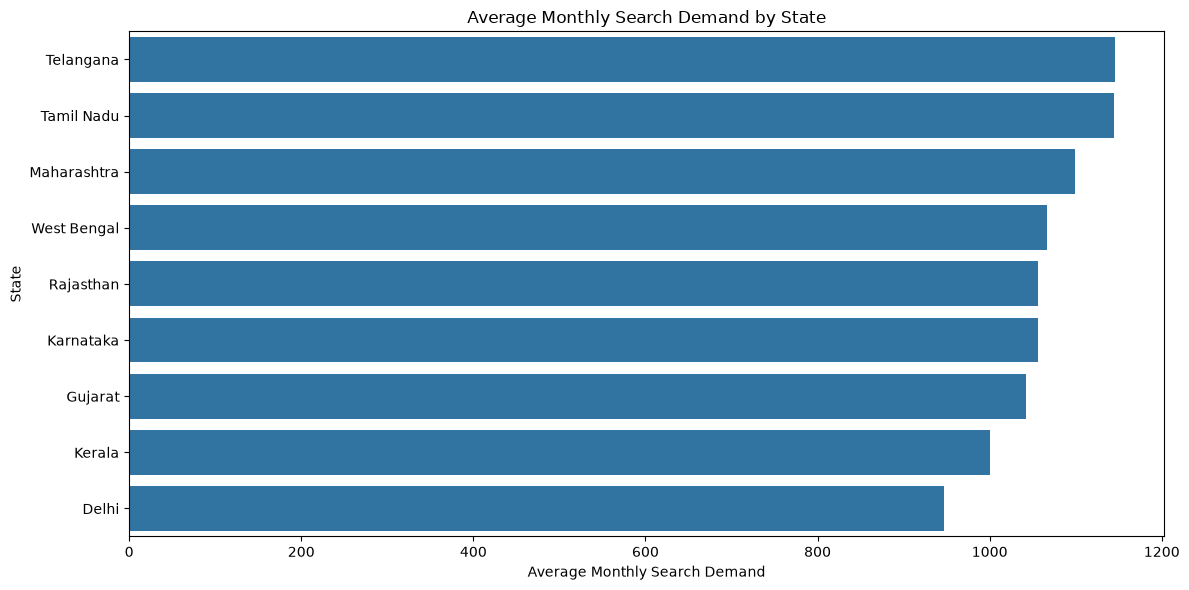

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_summary.sort_values(
        "AverageMonthlyDemand", ascending=False
    ),
    x="AverageMonthlyDemand",
    y="State"
)

plt.title("Average Monthly Search Demand by State")
plt.xlabel("Average Monthly Search Demand")
plt.ylabel("State")
plt.tight_layout()
plt.show()

### Create interactive geographic map
We'll plot the supplied latitude and longitude coordinates on a Folium map. Each marker will show the city's market indicators, and the color will represent its opportunity score.

In [17]:
from folium.plugins import MarkerCluster
import branca.colormap as cm

# Center the map on the available records
center_lat = geo_df["Latitude"].mean()
center_lon = geo_df["Longitude"].mean()

market_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=5,
    tiles="OpenStreetMap"
)

# Green = higher screening score, red = lower screening score
score_min = geo_df["OpportunityScore"].min()
score_max = geo_df["OpportunityScore"].max()

if score_min == score_max:
    score_max = score_min + 1

colormap = cm.LinearColormap(
    colors=["red", "orange", "green"],
    vmin=score_min,
    vmax=score_max,
    caption="Relative Market Opportunity Score"
)

cluster = MarkerCluster(name="Regional Market Locations")

for _, row in geo_df.iterrows():
    color = colormap(row["OpportunityScore"])

    popup_html = f"""
    <b>City:</b> {row['City']}<br>
    <b>State:</b> {row['State']}<br>
    <b>Region ID:</b> {row['RegionID']}<br>
    <b>Monthly Demand:</b> {row['MonthlySearchDemand']:,}<br>
    <b>Existing Competitors:</b> {row['ExistingCompetitors']}<br>
    <b>Lead Conversion:</b> {row['LeadConversionRate']:.2%}<br>
    <b>Annual Median Income:</b> ₹{row['MedianAnnualIncomeINR']:,}<br>
    <b>Acquisition Cost:</b> ₹{row['EstimatedAcquisitionCostINR']:,}<br>
    <b>Opportunity Score:</b> {row['OpportunityScore']:.3f}
    """

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=5,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.75,
        weight=1,
        tooltip=f"{row['City']}, {row['State']}",
        popup=folium.Popup(popup_html, max_width=300)
    ).add_to(cluster)

cluster.add_to(market_map)
colormap.add_to(market_map)

folium.LayerControl().add_to(market_map)

market_map

### Export the map to HTML

In [18]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

map_path = output_dir / "regional_market_map.html"

market_map.save(str(map_path))

print("Interactive map saved to:", map_path.resolve())

Interactive map saved to: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Geospatial Data Analysis\notebook\output\regional_market_map.html


### Identify the top 3 underserved regions
Let's use a two-part approach:
1. Filter for regions with relatively high demand and relatively low competition.
2. Rank those candidates by the opportunity score, then review conversion rate and acquisition cost before recommending them.

### Shortlist candidate locations

In [19]:
demand_threshold = geo_df["MonthlySearchDemand"].quantile(0.75)
competition_threshold = geo_df["ExistingCompetitors"].quantile(0.50)

candidates = geo_df[
    (geo_df["MonthlySearchDemand"] >= demand_threshold)
    & (geo_df["ExistingCompetitors"] <= competition_threshold)
].copy()

top_regions = candidates.sort_values(
    "OpportunityScore", ascending=False
).head(3)

columns_to_show = [
    "RegionID",
    "City",
    "State",
    "MonthlySearchDemand",
    "ExistingCompetitors",
    "LeadConversionRate",
    "EstimatedAcquisitionCostINR",
    "OpportunityScore",
]

display(top_regions[columns_to_show].round(3))

,RegionID,City,State,MonthlySearchDemand,ExistingCompetitors,LeadConversionRate,EstimatedAcquisitionCostINR,OpportunityScore
26,REG-0027,Kochi,Kerala,1816,1,0.138,613,0.973
352,REG-0353,Kolkata,West Bengal,1799,1,0.136,727,0.964
205,REG-0206,Kochi,Kerala,1787,1,0.130,407,0.952


### Export the regional summary and shortlist

In [20]:
state_summary.to_csv(
    output_dir / "state_market_summary.csv",
    index=False
)

top_regions[columns_to_show].to_csv(
    output_dir / "top_3_expansion_regions.csv",
    index=False
)

geo_df.to_csv(
    output_dir / "cleaned_regional_market_data.csv",
    index=False
)

print("Regional analysis CSV files exported successfully.")

Regional analysis CSV files exported successfully.


In [21]:
print(state_summary.head(5).round(2).to_string(index=False))
print("\nTop 3 candidates:")
print(top_regions[columns_to_show].round(3).to_string(index=False))

      State  Regions  Cities  TotalMonthlyDemand  AverageMonthlyDemand  TotalCompetitors  AverageCompetitors  AverageIncomeINR  AverageConversionRate  AverageAcquisitionCostINR  AverageOpportunityScore
Maharashtra       69       2               75849               1099.26               526                7.62         664141.33                   0.08                     469.97                     0.52
 Tamil Nadu       47       1               53771               1144.06               373                7.94         678182.09                   0.08                     411.68                     0.53
      Delhi       56       1               53007                946.55               449                8.02         701424.14                   0.07                     486.23                     0.46
    Gujarat       50       1               52110               1042.20               419                8.38         710723.80                   0.08                     487.00                

### Verify results

In [22]:
print("Cleaned dataset:", geo_df.shape)
print("Number of states:", geo_df["State"].nunique())
print("Number of cities:", geo_df["City"].nunique())

print("\nTop 3 expansion candidates:")
display(
    top_regions[
        [
            "City",
            "State",
            "MonthlySearchDemand",
            "ExistingCompetitors",
            "LeadConversionRate",
            "EstimatedAcquisitionCostINR",
            "OpportunityScore",
        ]
    ].round(3)
)

Cleaned dataset: (400, 16)
Number of states: 9
Number of cities: 10

Top 3 expansion candidates:


,City,State,MonthlySearchDemand,ExistingCompetitors,LeadConversionRate,EstimatedAcquisitionCostINR,OpportunityScore
26,Kochi,Kerala,1816,1,0.138,613,0.973
352,Kolkata,West Bengal,1799,1,0.136,727,0.964
205,Kochi,Kerala,1787,1,0.130,407,0.952


### Generate the PDF report

In [23]:

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from pathlib import Path
import pandas as pd

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

pdf_path = output_dir / "Geospatial_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=landscape(A4),
    rightMargin=35,
    leftMargin=35,
    topMargin=35,
    bottomMargin=35
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=18
))

story = []

story.append(Paragraph(
    "Geospatial Data Analysis",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Regional Market Expansion Opportunities in India",
    styles["Heading2"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("1. Executive Summary", styles["Heading1"]))
story.append(Paragraph(
    f"The supplied dataset contains {len(df)} original records. "
    f"After geographic validation and identifier checks, "
    f"{len(geo_df)} records remain for analysis. "
    f"The analysis compares search demand, competition, conversion "
    f"rates, acquisition costs and relative market opportunity scores.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("2. Methodology", styles["Heading1"]))
story.append(Paragraph(
    "The workflow includes dataset inspection, data cleaning, "
    "coordinate validation, state-level aggregation and interactive "
    "mapping using Folium. The screening score weights normalized "
    "demand at 50%, low competition at 30%, and conversion rate at 20%. "
    "Acquisition cost is assessed separately. This score is a relative "
    "screening metric and has not been validated as a profit prediction.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("3. State-Level Market Summary", styles["Heading1"]))

state_report = state_summary.head(10).copy()
state_report = state_report[
    [
        "State", "Regions", "TotalMonthlyDemand",
        "AverageMonthlyDemand", "AverageCompetitors",
        "AverageConversionRate", "AverageAcquisitionCostINR"
    ]
]

table_data = [[
    "State", "Regions", "Total Demand",
    "Avg Demand", "Avg Competitors",
    "Avg Conversion", "Avg Acquisition Cost (INR)"
]]

for _, r in state_report.iterrows():
    table_data.append([
        str(r["State"]),
        str(int(r["Regions"])),
        f'{r["TotalMonthlyDemand"]:,.0f}',
        f'{r["AverageMonthlyDemand"]:,.1f}',
        f'{r["AverageCompetitors"]:.2f}',
        f'{r["AverageConversionRate"]:.2%}',
        f'{r["AverageAcquisitionCostINR"]:,.0f}'
    ])

table = Table(
    table_data,
    repeatRows=1,
    colWidths=[105, 48, 75, 72, 82, 75, 120]
)
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1),
     [colors.white, colors.HexColor("#EAF0F8")]),
    ("LEFTPADDING", (0, 0), (-1, -1), 5),
    ("RIGHTPADDING", (0, 0), (-1, -1), 5),
]))
story.append(table)
story.append(Spacer(1, 16))

story.append(Paragraph("4. Top Expansion Candidates", styles["Heading1"]))

if len(top_regions) == 0:
    story.append(Paragraph(
        "No regions met the initial high-demand, low-competition "
        "screening criteria. The selection thresholds should be "
        "reviewed and documented before making recommendations.",
        styles["BodyText"]
    ))
else:
    candidate_data = [[
        "City", "State", "Demand", "Competitors",
        "Conversion", "Acquisition Cost (INR)", "Score"
    ]]

    for _, r in top_regions.iterrows():
        candidate_data.append([
            str(r["City"]),
            str(r["State"]),
            f'{r["MonthlySearchDemand"]:,.0f}',
            str(int(r["ExistingCompetitors"])),
            f'{r["LeadConversionRate"]:.2%}',
            f'{r["EstimatedAcquisitionCostINR"]:,.0f}',
            f'{r["OpportunityScore"]:.3f}'
        ])

    candidate_table = Table(
        candidate_data,
        repeatRows=1,
        colWidths=[100, 105, 65, 75, 75, 120, 60]
    )
    candidate_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#EAF0F8")]),
    ]))
    story.append(candidate_table)

story.append(Spacer(1, 16))
story.append(Paragraph("5. Geographic Visualization", styles["Heading1"]))
story.append(Paragraph(
    "The accompanying interactive HTML map displays supplied location "
    "coordinates and market indicators. Open regional_market_map.html "
    "in a browser to inspect individual records and their opportunity scores.",
    styles["BodyText"]
))
story.append(Spacer(1, 12))

story.append(Paragraph("6. Limitations and Recommendations", styles["Heading1"]))
story.append(Paragraph(
    "The supplied data is synthetic and contains no direct sales or "
    "revenue measurements. Search demand is used as a demand proxy, "
    "while competitor counts are used as a competition proxy. The "
    "coordinates have been checked against broad geographic bounds, "
    "but not independently verified against city boundaries. "
    "Before expansion, validate local demand, actual customer acquisition "
    "costs, competitor coverage and expected profitability. Treat the "
    "ranked regions as candidates for further investigation rather than "
    "confirmed underserved markets.",
    styles["BodyText"]
))

doc.build(story)

print("PDF report created:", pdf_path.resolve())


PDF report created: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Geospatial Data Analysis\notebook\output\Geospatial_Analysis_Report.pdf


In [24]:
from pathlib import Path

for file_path in sorted(Path("output").glob("*")):
    print(
        file_path.name,
        "-",
        f"{file_path.stat().st_size:,} bytes"
    )

cleaned_regional_market_data.csv - 69,603 bytes
Geospatial_Analysis_Report.pdf - 5,159 bytes
regional_market_map.html - 661,826 bytes
state_market_summary.csv - 1,295 bytes
top_3_expansion_regions.csv - 312 bytes
